# Module 1 — Rigorous Correlation Analysis

**By the end of this notebook, you will be able to:**
- Read a correlation coefficient together with its p-value, and know why neither is enough alone
- Avoid a common correlation-analysis bug: computing p-values pairwise instead of dropping rows across every column at once
- Build and interpret a correlation heatmap that only shows statistically significant relationships

**Context:** In the discovery notebook (Session 2), you saw a first, quick correlation heatmap on Kampala and Nairobi only. Here, you do it properly: on the full dataset (Kampala, Nairobi, Lagos, and Bujumbura), with Pearson **and** Spearman correlation, their p-values, and a heatmap that only shows what is actually reliable.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

CITIES = ["Kampala", "Nairobi", "Lagos", "Bujumbura"]
COLUMNS = [
    "city", "date", "hour", "site_latitude", "site_longitude", "pm2_5",
    "sulphurdioxide_so2_column_number_density",
    "carbonmonoxide_co_column_number_density",
    "nitrogendioxide_no2_column_number_density",
    "formaldehyde_tropospheric_hcho_column_number_density",
    "uvaerosolindex_absorbing_aerosol_index",
    "ozone_o3_column_number_density",
    "uvaerosollayerheight_aerosol_height",
    "cloud_cloud_fraction",
]

df = pd.read_csv("../../data/train.csv")
df = df[df["city"].isin(CITIES)][COLUMNS].copy()
df["date"] = pd.to_datetime(df["date"])
df["city"].value_counts()

city
Kampala      5596
Nairobi      1500
Lagos         852
Bujumbura     123
Name: count, dtype: int64

## Correlation with `pm2_5`

A single correlation number is not enough:

- **Pearson's r** measures *linear* correlation and is sensitive to outliers.
- **Spearman's rho** measures *monotonic* correlation using ranks, so it is more robust to outliers and non-linear (but still monotonic) relationships.
- The **p-value** estimates how likely it would be to observe a correlation this strong by chance alone if the true correlation were zero. A coefficient without a p-value tells you nothing about whether it could just be noise — and a low p-value does not mean the relationship is strong, only that it is unlikely to be pure chance. Neither implies causation.

For a deeper treatment of p-values — common misconceptions, how to read them alongside the coefficient, when they can mislead — see [section 7 of Machine Learning Techniques: From Theory to Practice](https://hub.imt-atlantique.fr/datascience-toolkit/courses/lesson_1/#7-focus-on-p-value).

**Documentation references:**
- [`scipy.stats.pearsonr()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)
- [`scipy.stats.spearmanr()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)
- [`DataFrame.dropna()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html)

**Exercise:** Write a function that computes, for one column against `pm2_5`, both Pearson and Spearman correlation together with their p-values. Before correlating, restrict the data to rows where **both of those two columns** (not all 8) have a value — `DataFrame.dropna()` accepts a `subset` of columns to check, so you don't have to select the columns manually first. This matters because `uvaerosollayerheight_aerosol_height` alone is missing over 90% of the time: requiring all 8 columns to be present simultaneously would collapse the usable sample and bias every correlation, not just that one variable's.

In [4]:
# TODO 1: define a function that computes Pearson and Spearman correlation (with p-values)
# between one column and the target, dropping missing values for that pair only
def correlate_with_target(df, column, target_col):
    """Compute pairwise Pearson and Spearman statistics against the target."""
    pair = df[[column, target_col]].dropna()
    pearson = stats.pearsonr(pair[column], pair[target_col])
    spearman = stats.spearmanr(pair[column], pair[target_col])
    return {
        "n": len(pair),
        "pearson_r": pearson.statistic,
        "pearson_p": pearson.pvalue,
        "spearman_r": spearman.statistic,
        "spearman_p": spearman.pvalue,
    }


**Exercise:** Apply `correlate_with_target` to every satellite column against `pm2_5`, collect the results in a DataFrame, and sort it by the strength of the Pearson correlation (largest absolute value first).

In [5]:
# TODO 2: apply correlate_with_target to every satellite column, and sort the results
satellite_columns = [column for column in COLUMNS if column not in {
    "city", "date", "hour", "site_latitude", "site_longitude", "pm2_5"
}]
correlation_table = pd.DataFrame([
    {"column": column, **correlate_with_target(df, column, "pm2_5")}
    for column in satellite_columns
])
correlation_table = correlation_table.sort_values(
    "pearson_r", key=lambda values: values.abs(), ascending=False
).reset_index(drop=True)
correlation_table


,column,n,pearson_r,pearson_p,spearman_r,spearman_p
0,carbonmonoxide_co_column_number_density,4441,0.422418,9.933361e-192,0.518714,1.752288e-304
1,nitrogendioxide_no2_column_number_density,3104,0.398677,9.096420e-119,0.430961,1.333185e-140
2,formaldehyde_tropospheric_hcho_column_number_d...,4156,0.199219,1.824845e-38,0.279650,1.552626e-75
3,ozone_o3_column_number_density,7959,-0.182241,2.136937e-60,-0.222900,3.542736e-90
4,uvaerosolindex_absorbing_aerosol_index,8066,0.166570,2.841949e-51,0.129494,1.663594e-31
5,uvaerosollayerheight_aerosol_height,427,-0.036912,4.467900e-01,0.034227,4.805658e-01
6,cloud_cloud_fraction,4994,-0.019122,1.766588e-01,0.034310,1.532078e-02
7,sulphurdioxide_so2_column_number_density,3159,0.005587,7.535959e-01,-0.012192,4.933418e-01


### From one correlation to a full matrix

`correlation_table` compares every variable to `pm2_5`, one at a time. A **correlation matrix** compares every variable to every other variable at once — useful, but it is symmetric: the correlation between A and B is identical to the one between B and A, so a full heatmap would show every relationship twice (once above the diagonal, once below), plus a diagonal of 1s that isn't informative (a variable is always perfectly correlated with itself).

To keep only the useful half, and only the statistically significant cells, we build a **mask**: a same-shaped table of `True`/`False` where `True` means "hide this cell." `seaborn.heatmap` accepts a `mask=` argument for exactly this. We'll build it in a few small steps, then use it.

**Exercise:** Write a function that returns both the correlation matrix and the matching p-value matrix for a set of columns. `DataFrame.corr()` gives you the correlation matrix in one call. For the p-values, reuse the idea from `correlate_with_target` — pairwise `dropna`, then `pearsonr` — but applied to every *pair* of columns this time (a loop inside a loop), not just each column against `pm2_5`.

In [6]:
# TODO 3: define a function that returns the correlation matrix and the matching
# p-value matrix for a set of columns, reusing the pairwise-dropna idea from
# correlate_with_target (TODO 1) but for every pair of columns, not just one
# column against the target
def pairwise_correlation_matrices(df, columns):
    """Return Pearson correlations and pairwise-complete p-values."""
    corr = df[columns].corr(method="pearson")
    pvalue_matrix = pd.DataFrame(np.nan, index=columns, columns=columns, dtype=float)
    for i, first in enumerate(columns):
        pvalue_matrix.loc[first, first] = 1.0
        for second in columns[i + 1:]:
            pair = df[[first, second]].dropna()
            result = stats.pearsonr(pair[first], pair[second])
            pvalue_matrix.loc[first, second] = result.pvalue
            pvalue_matrix.loc[second, first] = result.pvalue
    return corr, pvalue_matrix


**Exercise:** Apply `pairwise_correlation_matrices` to `satellite_columns + ["pm2_5"]` to get `corr` and `pvalue_matrix`. Then build the mask in two parts and combine them with `|` (a cell is hidden if *either* is true): (1) `pvalue_matrix > 0.05` for the non-significant cells, and (2) the upper triangle, using [`numpy.triu`](https://numpy.org/doc/stable/reference/generated/numpy.triu.html) on a same-shaped array of `True` — check its `k` argument to exclude the diagonal itself (you want to hide the redundant mirror, not the variables' self-correlation row).

In [7]:
# TODO 4: apply pairwise_correlation_matrices, then build a mask that hides
# non-significant cells (p >= 0.05) and the redundant upper triangle
corr, pvalue_matrix = pairwise_correlation_matrices(df, satellite_columns + ["pm2_5"])
non_significant = pvalue_matrix >= 0.05
upper_triangle = pd.DataFrame(
    np.triu(np.ones(corr.shape, dtype=bool), k=1),
    index=corr.index,
    columns=corr.columns,
)
mask = non_significant | upper_triangle


**Exercise:** Draw the masked correlation heatmap with `seaborn.heatmap`, passing your `mask`.

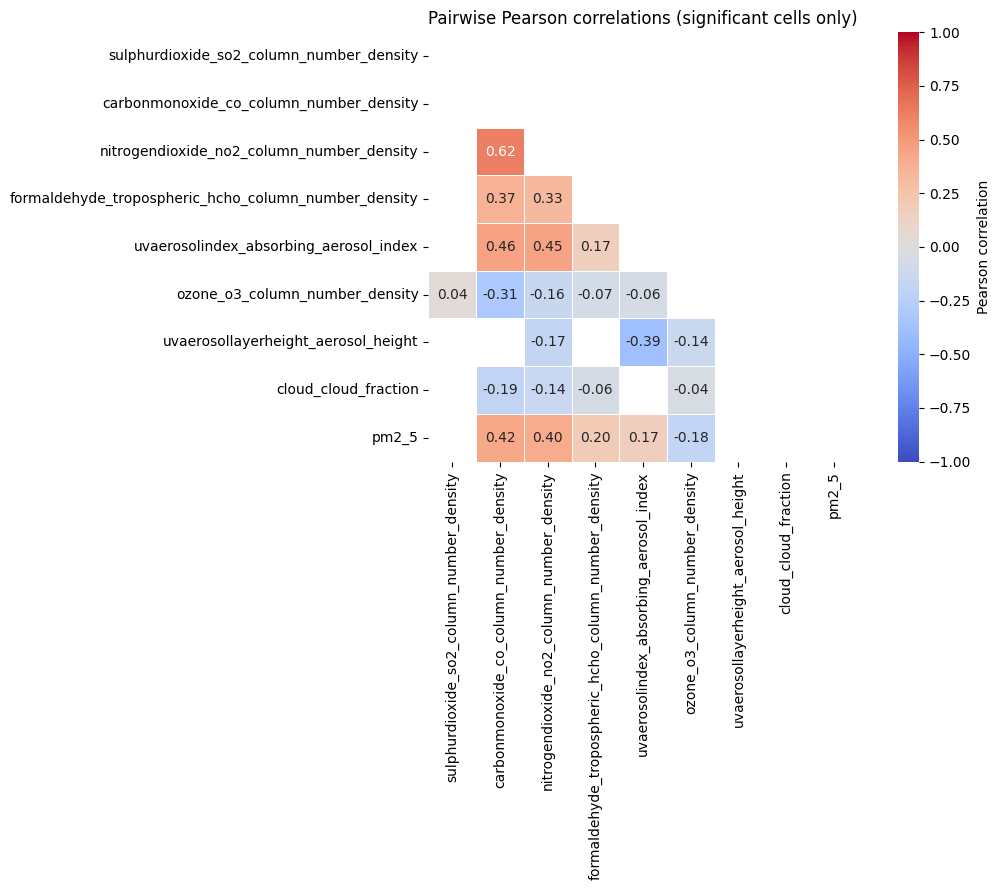

In [8]:
# TODO 5: draw the correlation heatmap, hiding masked cells
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Pairwise Pearson correlations (significant cells only)")
plt.tight_layout()
plt.show()


**Exercise:** Zoom in on the variable most correlated with `pm2_5` — the first row of `correlation_table`, already sorted — with a scatter plot and a regression line: [`seaborn.regplot`](https://seaborn.pydata.org/generated/seaborn.regplot.html). Include the Pearson r, its p-value, and the sample size `n` in the title, so the plot carries its own evidence.

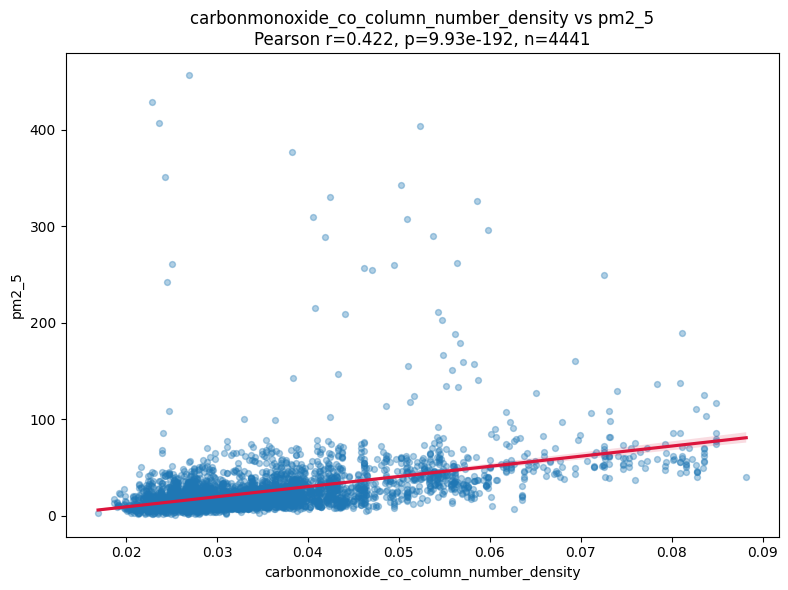

In [9]:
# TODO 6: scatter plot + regression line for the most correlated variable, with its
# statistics in the title
best = correlation_table.iloc[0]
best_column = best["column"]
plot_data = df[[best_column, "pm2_5"]].dropna()
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=plot_data, x=best_column, y="pm2_5", ax=ax,
            scatter_kws={"alpha": 0.35, "s": 18}, line_kws={"color": "crimson"})
ax.set_title(
    f"{best_column} vs pm2_5\nPearson r={best['pearson_r']:.3f}, "
    f"p={best['pearson_p']:.3g}, n={int(best['n'])}"
)
plt.tight_layout()
plt.show()


**Continue on the site:** [Module 1 — Rigorous Correlation Analysis](https://hub.imt-atlantique.fr/datascience-toolkit/session3/practical_1/)